In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('dataset_tugas1_preprocessing.csv')

# Menampilkan 5 baris pertama untuk memastikan data berhasil dimuat
df.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


In [3]:
# Cek struktur dan tipe data
df.info()

# Tampilkan jumlah nilai hilang per kolom
print(df.isnull().sum())

# Sajikan statistik deskriptif
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64


,Umur
count,90.000000
mean,23.366667
std,3.763963
min,18.000000
25%,20.000000
50%,23.000000
75%,26.000000
max,30.000000


In [5]:
# Gunakan mode()[0] (modus / nilai yang paling sering muncul) untuk data kategorikal
df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(df['Nilai_Akhir'].mode()[0])

# Umur biasanya numerik, jadi menggunakan mean() atau median() sudah tepat
df['Umur'] = df['Umur'].fillna(df['Umur'].mean())

In [6]:
# Mengonversi kolom Tanggal_Ujian ke format datetime
df['Tanggal_Ujian'] = pd.to_datetime(df['Tanggal_Ujian'], errors='coerce')

# (Opsional) Menampilkan info untuk memastikan tipe data sudah berubah menjadi datetime64
print(df['Tanggal_Ujian'].dtype)

datetime64[ns]


/tmp/ipykernel_5704/1313891581.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Tanggal_Ujian'] = pd.to_datetime(df['Tanggal_Ujian'], errors='coerce')


In [7]:
from sklearn.preprocessing import LabelEncoder

# Membuat objek LabelEncoder
le = LabelEncoder()

# Daftar kolom yang akan di-encode sesuai petunjuk tugas
kolom_kategori = ['Nama', 'Jenis_Kelamin', 'Prodi', 'Status', 'Nilai_Akhir']

# Melakukan perulangan (looping) untuk mengubah setiap kolom menjadi angka
for kolom in kolom_kategori:
    # astype(str) digunakan untuk berjaga-jaga jika ada tipe data campuran di dalam kolom
    df[kolom] = le.fit_transform(df[kolom].astype(str))

# Menampilkan 5 baris pertama untuk melihat hasil perubahannya
df.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,8,0,3,0,2,2020-04-13,23.366667
1,MH002,4,1,3,3,4,NaT,28.000000
2,MH003,8,0,3,0,2,NaT,23.000000
3,MH004,4,1,3,0,3,NaT,18.000000
4,MH005,9,1,0,0,2,NaT,26.000000


In [8]:
from sklearn.model_selection import train_test_split

# Memisahkan fitur (X) dan target (y).
# errors='ignore' digunakan agar jika kolom ID/Tanggal_Ujian tidak ada, tidak terjadi error.
X = df.drop(columns=['Status', 'ID', 'Tanggal_Ujian'], errors='ignore')
y = df['Status']

# Membagi data menjadi 80% latih dan 20% uji dengan parameter test_size=0.2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Jumlah data latih (80%):", len(X_train))
print("Jumlah data uji (20%):", len(X_test))

Jumlah data latih (80%): 79
Jumlah data uji (20%): 20


/tmp/ipykernel_5704/3812794154.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Prodi', palette='Set2')


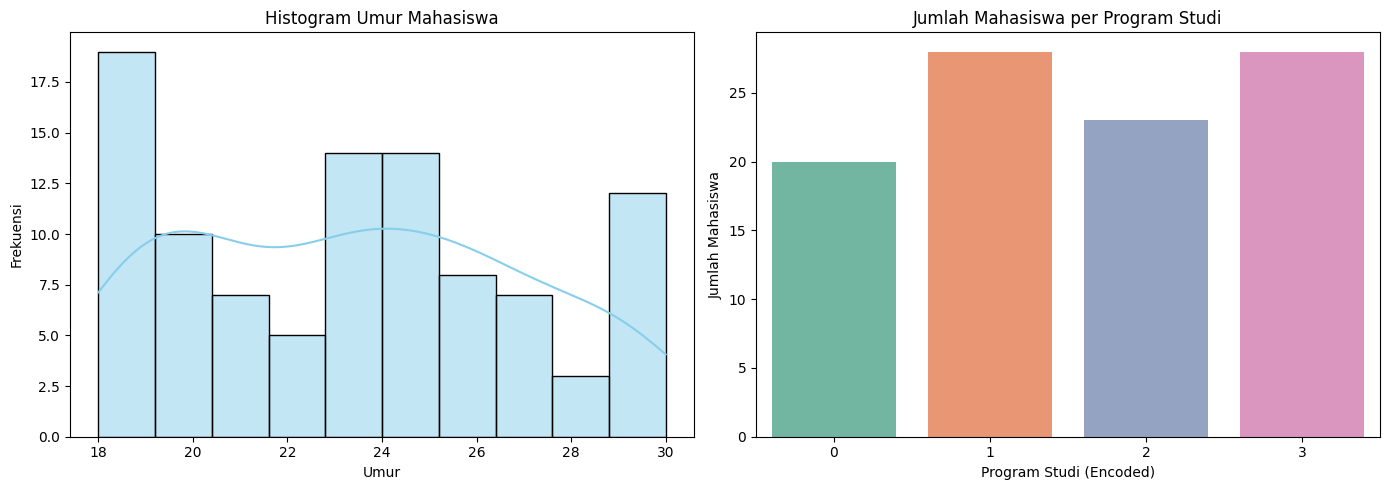

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat area gambar yang cukup luas untuk 2 grafik secara berdampingan
plt.figure(figsize=(14, 5))

# --- Grafik 1: Histogram untuk kolom Umur ---
plt.subplot(1, 2, 1)
sns.histplot(df['Umur'], bins=10, kde=True, color='skyblue')
plt.title('Histogram Umur Mahasiswa')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')

# --- Grafik 2: Grafik Batang (Bar Chart) jumlah mahasiswa per Prodi ---
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Prodi', palette='Set2')
plt.title('Jumlah Mahasiswa per Program Studi')
plt.xlabel('Program Studi (Encoded)')
plt.ylabel('Jumlah Mahasiswa')

# Menampilkan grafik agar rapi
plt.tight_layout()
plt.show()